The workflow is:

    Create an active learning pool with from_dataset().

    Pick a query strategy (MarginSampling or RandomQuery).

    Iterate with active_learning_steps().

    Evaluate with compute_accuracy(), compute_ece(), and compute_nauc()

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

from probly.evaluation.active_learning import (
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    compute_accuracy,
    compute_ece,
    compute_nauc,
    from_dataset,
)

SEED = 42
INITIAL_SIZE = 30
QUERY_SIZE = 30
N_ITERATIONS = 15

In [2]:
X, y = load_digits(return_X_y=True)
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
)

In [3]:
strategies = {
    "Margin Sampling": MarginSampling(),
    "Random": RandomQuery(seed=SEED),
}

results: dict[str, dict] = {}

for name, strategy in strategies.items():
    pool = from_dataset(
        x_train,
        y_train,
        x_test,
        y_test,
        initial_size=INITIAL_SIZE,
        seed=SEED,
    )
    estimator = LogisticRegression(max_iter=1000, random_state=SEED)

    accuracies: list[float] = []
    eces: list[float] = []
    labeled_sizes: list[int] = []

    for state in active_learning_steps(
        pool,
        estimator,
        strategy,
        query_size=QUERY_SIZE,
        n_iterations=N_ITERATIONS,
    ):
        preds = state.estimator.predict(state.pool.x_test)
        probs = state.estimator.predict_proba(state.pool.x_test)
        accuracies.append(compute_accuracy(preds, state.pool.y_test))
        eces.append(compute_ece(probs, state.pool.y_test))
        labeled_sizes.append(state.pool.n_labeled)

    # NAUC (normalized area under the accuracy curve) summarizes how quickly
    # a strategy reaches good accuracy. Higher is better.
    nauc = compute_nauc(accuracies)
    results[name] = {
        "accuracies": accuracies,
        "eces": eces,
        "labeled_sizes": labeled_sizes,
    }
    print(f"{name:20s}  final acc: {accuracies[-1]:.3f}  ECE: {eces[-1]:.3f}  NAUC: {nauc:.3f}")

Margin Sampling       final acc: 0.975  ECE: 0.022  NAUC: 0.948
Random                final acc: 0.933  ECE: 0.030  NAUC: 0.925


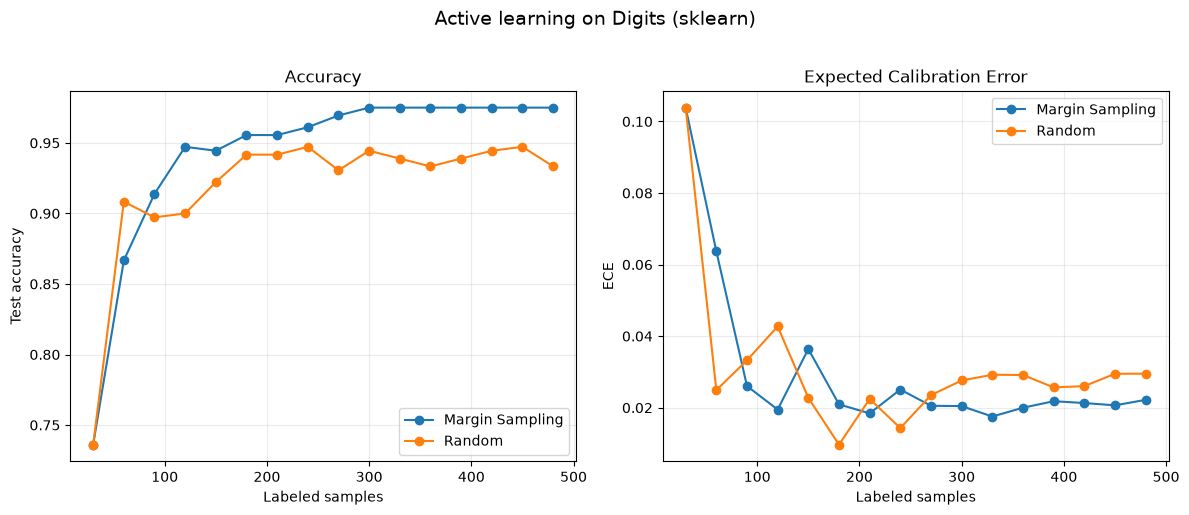

In [4]:
fig, (ax_acc, ax_ece) = plt.subplots(1, 2, figsize=(12, 5))

for name, data in results.items():
    ax_acc.plot(data["labeled_sizes"], data["accuracies"], marker="o", label=name)
    ax_ece.plot(data["labeled_sizes"], data["eces"], marker="o", label=name)

ax_acc.set_xlabel("Labeled samples")
ax_acc.set_ylabel("Test accuracy")
ax_acc.set_title("Accuracy")
ax_acc.legend()
ax_acc.grid(alpha=0.25)

ax_ece.set_xlabel("Labeled samples")
ax_ece.set_ylabel("ECE")
ax_ece.set_title("Expected Calibration Error")
ax_ece.legend()
ax_ece.grid(alpha=0.25)

fig.suptitle("Active learning on Digits (sklearn)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()